Ce notebook présente le modèle SVMR aprés un préprocessing strict commun 

In [14]:
#Importation du fichier pour l'entrainement du modèle
import pandas as pd

df = pd.read_csv("../data/final_metropole/donnees_modeles.csv", dtype={"code_dept": str})

pas_variables = ["date_semaine", "date_cible", "annee", "annee_cible", "semaine", "jeu",
                 "TousAge_allergie_urgences", "cible", "pic", "moy4", "population"]
variables = [c for c in df.columns if c not in pas_variables]

#Séparation des jeux train, val, test
train = df[df["jeu"] == "train"]
val = df[df["jeu"] == "val"]
test = df[df["jeu"] == "test"]
train_val = df[df["jeu"] != "test"]

X_train, y_train = train[variables], train["cible"]
X_val, y_val = val[variables], val["cible"]
X_test, y_test = test[variables], test["cible"]
X_train_val, y_train_val = train_val[variables], train_val["cible"]

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19680 entries, 0 to 19679
Data columns (total 69 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19680 non-null  str    
 1   code_dept                                   19680 non-null  str    
 2   As in PM10                                  19680 non-null  float64
 3   BaP in PM10                                 19680 non-null  float64
 4   Cd in PM10                                  19680 non-null  float64
 5   Ni in PM10                                  19680 non-null  float64
 6   Pb in PM10                                  19680 non-null  float64
 7   NO2                                         19680 non-null  float64
 8   O3                                          19680 non-null  float64
 9   PM10                                        19680 non-null  float64
 10  PM2.5                

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

# Construction du préprocesseur pour le svmr
preprocessor_svr = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ]
)

# Application (Fit sur le Train uniquement, Transform Test)
X_train_svr = preprocessor_svr.fit_transform(X_train_val)
X_test_svr = preprocessor_svr.transform(X_test)

print('\nDimensions après preprocessing SVMR :')
print(f'X_train_svr : {X_train_svr.shape}')
print(f'X_test_svr  : {X_test_svr.shape}')


Dimensions après preprocessing SVMR :
X_train_svr : (14688, 153)
X_test_svr  : (4992, 153)


Entraînement, Optimisation du Modèle 

In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.svm import SVR


# Fonction d'affichage rapide pour standardiser les résultats
def eval_metrics(y_true, y_pred, name_split, name_model):
  r2 = r2_score(y_true, y_pred)
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  print(
      f"[{name_model}] {name_split} -> R2: {r2:.4f} | RMSE: {rmse:.4f} | MAE:"
      f" {mae:.4f}"
  )


# Instanciation directe avec les hyperparamètres optimaux retenus
svr = SVR(kernel="rbf", C=100, epsilon=1.5, gamma=0.01)
svr.fit(X_train_svr, y_train_val)

# Prédictions
y_pred_train = svr.predict(X_train_svr)
y_pred_test = svr.predict(X_test_svr)

# Évaluation finale
print("\n--- Performances Finales SVR Optimisé ---")
eval_metrics(y_train_val, y_pred_train, "Train", "SVR Opt")
eval_metrics(y_test, y_pred_test, "Test", "SVR Opt")



--- Performances Finales SVR Optimisé ---
[SVR Opt] Train -> R2: 0.4883 | RMSE: 231.1967 | MAE: 161.5205
[SVR Opt] Test -> R2: 0.4072 | RMSE: 225.6500 | MAE: 163.4563


représentation résultats et comparaison entre prédict et réel

Visualisation graphique d'une courbe temporelle sur des départements de référence

13 (Bouches-du-Rhône) : Fort volume, zone urbaine dense, idéal pour tester la robustesse sur un grand nombre de cas.

34 (Hérault): Très forte exposition aux pollens méditerranéens (cyprès, platanes) avec des pics saisonniers extrêmement violents.

06 (Alpes-Maritimes) : Profil mixte littoral/montagne avec des microclimats spécifiques.

84 (Vaucluse) : Zone semi-rurale/agricole avec une exposition aux cultures et végétations locales différente des grands centres urbains.


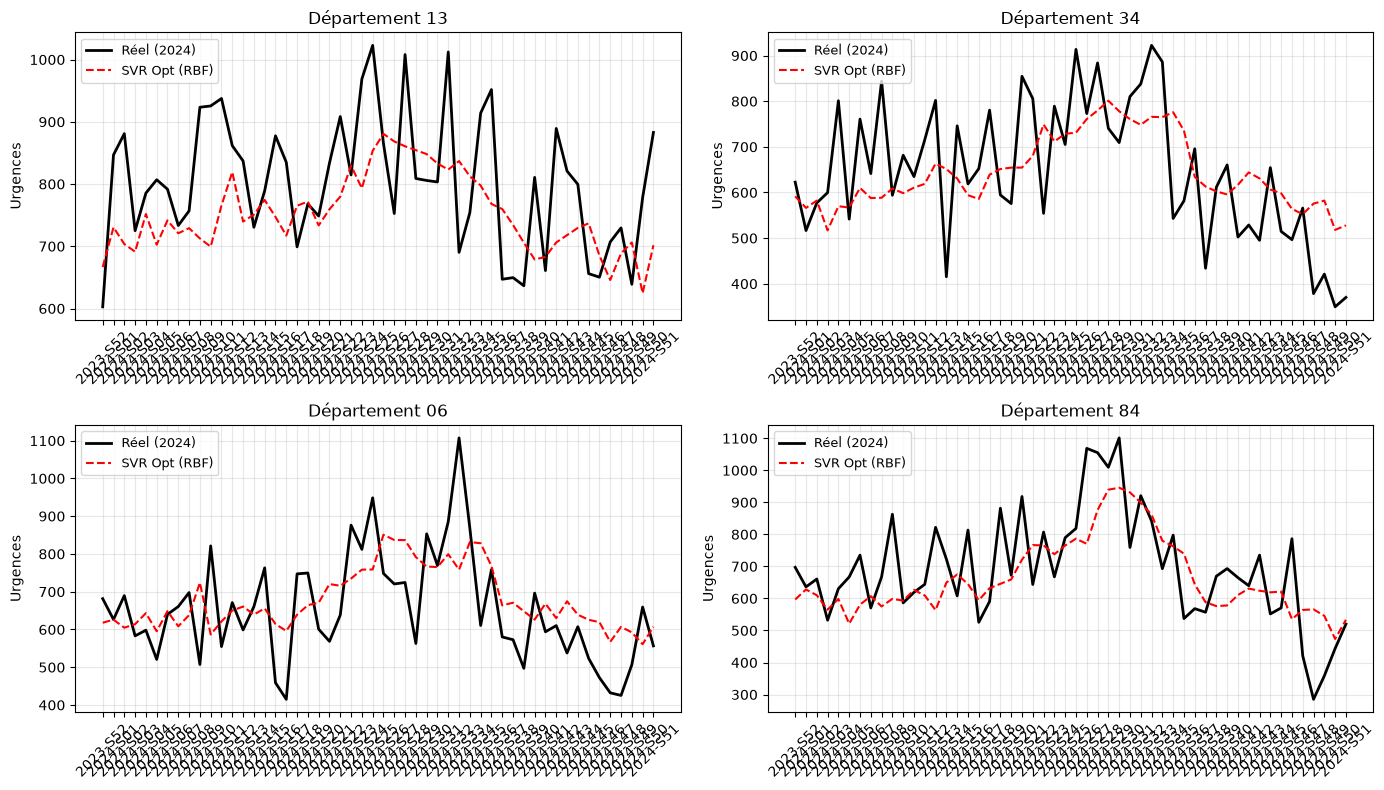

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

# Ajout des prédictions SVR dans une copie du DataFrame de test
test_viz = test.copy()
test_viz['pred_svr'] = y_pred_test

# Sélection des départements d'intérêt
depts_cibles = ['13', '34', '06', '84']

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=False)
axes = axes.flatten()

for i, dept in enumerate(depts_cibles):
  ax = axes[i]
  sub_df = test_viz[test_viz['code_dept'] == dept]

  ax.plot(
      sub_df['date_semaine'],
      sub_df['cible'],
      label='Réel (2024)',
      color='black',
      linewidth=2,
  )
  ax.plot(
      sub_df['date_semaine'],
      sub_df['pred_svr'],
      label='SVR Opt (RBF)',
      color='red',
      linestyle='--',
      linewidth=1.5,
  )

  ax.set_title(f'Département {dept}')
  ax.set_ylabel('Urgences')
  ax.legend(loc='upper left', fontsize=9)
  ax.grid(True, alpha=0.3)
  ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Analyse de l'importance des variables

--- Top 10 des variables les plus importantes (SVR RBF) ---
                                 feature  importance_mean  importance_std
                        moyenne_passe_2w         0.140367        0.004176
                      temperature_kelvin         0.043315        0.004772
                             semaine_cos         0.036777        0.005225
                              pct_urbain         0.027572        0.001013
                    lag_2_semaines_avant         0.023904        0.000986
prev_calc_Maladie_Respi_Chronique_0-14_9         0.021205        0.002210
                    densite_generalistes         0.020542        0.002678
                            pct_employes         0.011117        0.001089
                       densite_pediatres         0.005146        0.001053
    prev_Maladie_Respi_Chronique_tsage_9         0.004879        0.000591


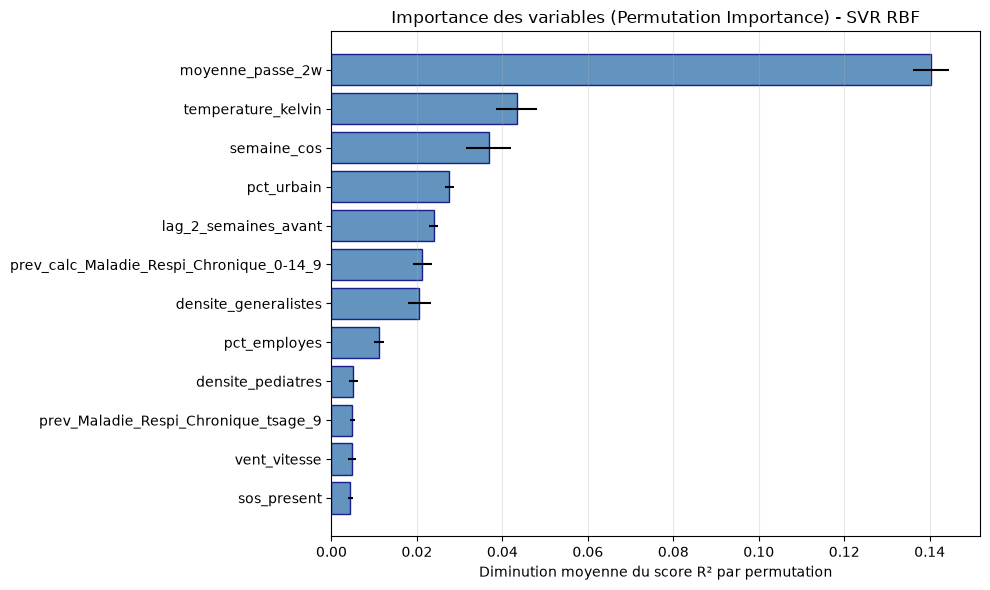

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance

#Calcul de la permutation importance sur le jeu de test (2024)
result = permutation_importance(
    svr,
    X_test_svr,
    y_test,
    scoring='r2',
    n_repeats=5,  # 5 répétitions pour stabiliser l'écart-type tout en restant rapide sur SVR
    random_state=42,
    n_jobs=-1,
)

#Récupération automatique des noms de features
if hasattr(X_test_svr, 'columns'):
  all_feature_names = X_test_svr.columns.tolist()
else:
  # Nettoyage des préfixes 'num__' et 'cat__' générés par ColumnTransformer
  all_feature_names = [
      name.split('__')[-1]
      for name in preprocessor_svr.get_feature_names_out()
  ]

#Création du DataFrame récapitulatif trié
importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std,
}).sort_values('importance_mean', ascending=False)

print('--- Top 10 des variables les plus importantes (SVR RBF) ---')
print(importance_df.head(10).to_string(index=False))

#Visualisation graphique
plt.figure(figsize=(10, 6))
top_features = importance_df.head(12).iloc[::-1]

plt.barh(
    top_features['feature'],
    top_features['importance_mean'],
    xerr=top_features['importance_std'],
    color='steelblue',
    edgecolor='navy',
    alpha=0.85,
)
plt.xlabel('Diminution moyenne du score R² par permutation')
plt.title('Importance des variables (Permutation Importance) - SVR RBF')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

  0%|          | 0/150 [00:00<?, ?it/s]

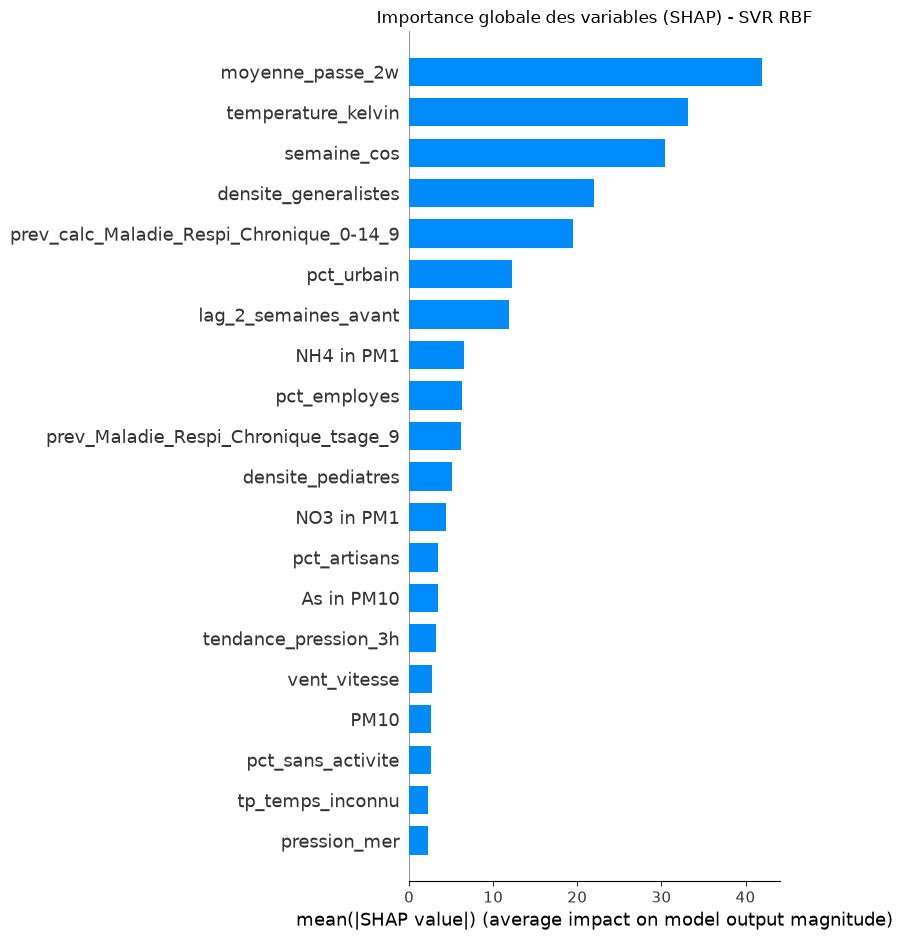

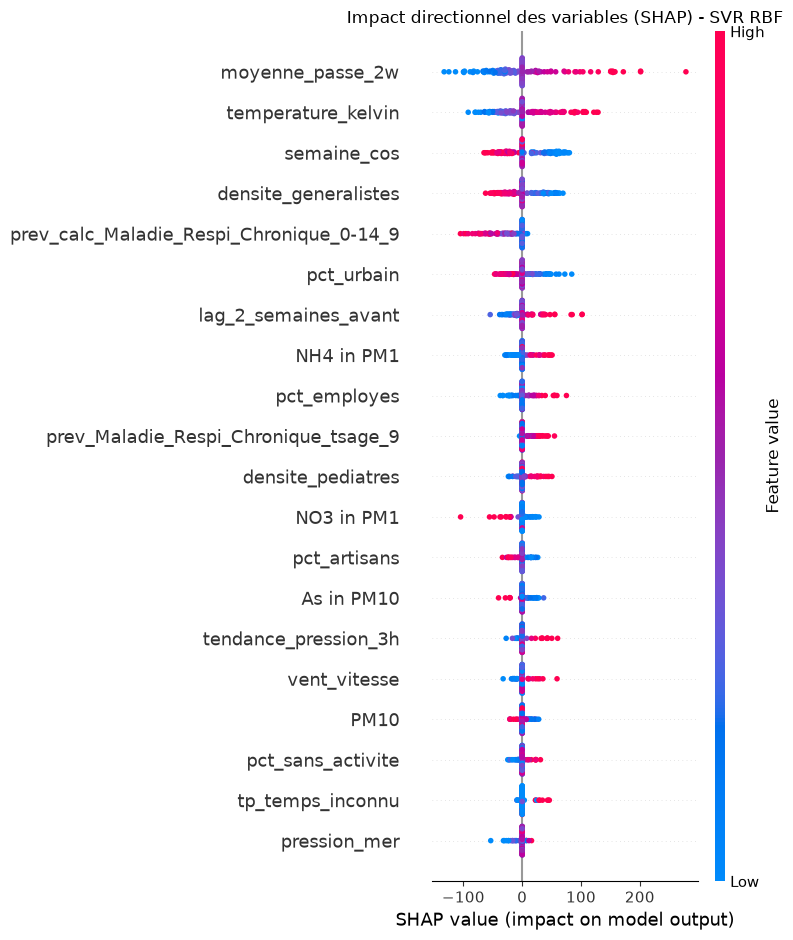

In [23]:
import shap

# Récupération propre des noms de colonnes (sans préfixes 'num__' / 'cat__')
if hasattr(X_test_svr, "columns"):
  noms_colonnes = X_test_svr.columns.tolist()
  X_train_svr_df = X_train_svr.copy()
  X_test_svr_df = X_test_svr.copy()
else:
  noms_colonnes = [
      col.split("__")[-1] for col in preprocessor_svr.get_feature_names_out()
  ]
  X_train_svr_df = pd.DataFrame(X_train_svr, columns=noms_colonnes)
  X_test_svr_df = pd.DataFrame(X_test_svr, columns=noms_colonnes)

# Résumé du jeu d'entraînement via K-Means pour accélérer KernelExplainer
X_train_summary = shap.kmeans(X_train_svr_df, 5)

# Initialisation de l'explainer avec le nouveau modèle 'svr'
explainer = shap.KernelExplainer(svr.predict, X_train_summary)

# Échantillonnage aléatoire sur 2024 (évite de ne prendre que janvier avec .head())
X_test_sample = X_test_svr_df.sample(
    n=min(150, len(X_test_svr_df)), random_state=42
)
shap_values = explainer.shap_values(X_test_sample, nsamples=150)

# Importance globale (Bar plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Importance globale des variables (SHAP) - SVR RBF")
plt.tight_layout()
plt.show()

# Graphique d'impact directionnel (Beeswarm plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("Impact directionnel des variables (SHAP) - SVR RBF")
plt.tight_layout()
plt.show()

In [24]:
#export modele entrainer pour le Streamlit
import joblib

joblib.dump(svr, "../Streamlit/Modeles/svmrfinal.pkl")

['../Streamlit/Modeles/svmrfinal.pkl']